## Student Retention Project



### Overview

This longitudinal panel dataset is designed to support predictive modeling, risk profiling, and machine learning research focused on higher-education student retention.

It contains 79,239 synthetic semester-level records, tracking students across multiple academic terms for up to 8 semesters. The dataset captures a holistic view of the student experience by combining:

* Demographic information
* Socioeconomic and financial constraints
* Academic performance
* Semester-level progression
* Learning engagement indicators
* Attrition and retention risk factors

The primary objective is to model the probability of future student attrition through the target variable:
`Target_Dropout_Next_Sem`


Data set could be found at: https://www.kaggle.com/datasets/razanihababdellatif/student-retention-and-academic-performance-data

In [94]:
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.ticker import MultipleLocator, FuncFormatter
import seaborn as sns

### Read data set from CSV

In [95]:
# Read CSV
CSV_PATH = "academic_survival_longitudinal.csv"

df_raw = pd.read_csv(CSV_PATH)
print("Data set shape (rows, cols): ", df_raw.shape)

display(df_raw.head())

Data set shape (rows, cols):  (79239, 22)


,Student_ID,Age,Gender,First_Generation,Family_Income,Household_Size,Housing_Status,Scholarship,Tuition_Base,Semester,...,Emergency_Expense,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,End_of_Semester_Status,Censored
0,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,1,...,0.0,2.85,85.8,67.0,0,0,1.7,0,Enrolled,0
1,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,2,...,0.0,2.73,81.0,89.0,1,0,3.1,0,Enrolled,0
2,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,3,...,0.0,2.60,78.3,60.0,0,2,3.0,0,Enrolled,0
3,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,4,...,0.0,2.34,77.2,59.0,2,3,5.1,0,Enrolled,0
4,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,5,...,0.0,1.90,79.3,53.0,1,2,3.6,0,Enrolled,1


### Data cleaning and processing

In this section we review the dataset columns and perform any necessary cleaning steps. We display the data types and check for the missing values and do small transformations if that is the case.

In [96]:
# Display data information
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79239 entries, 0 to 79238
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Student_ID               79239 non-null  object 
 1   Age                      79239 non-null  int64  
 2   Gender                   79239 non-null  object 
 3   First_Generation         79239 non-null  int64  
 4   Family_Income            75635 non-null  float64
 5   Household_Size           79239 non-null  int64  
 6   Housing_Status           79239 non-null  object 
 7   Scholarship              79239 non-null  int64  
 8   Tuition_Base             79239 non-null  int64  
 9   Semester                 79239 non-null  int64  
 10  Course_Load              79239 non-null  int64  
 11  Work_Hours               79239 non-null  float64
 12  Emergency_Expense        79239 non-null  float64
 13  Sem_GPA                  79239 non-null  float64
 14  Attendance            

In [97]:
# Check for missing values
missing_values = df_raw.isnull().sum()
print("Missing values based on columns: \n")
display(missing_values[missing_values > 0])

Missing values based on columns: 



,0
Family_Income,3604
LMS_Logins,867


Family_Income mean:  61518.38434587162
Family_Income median:  52000.0
Family_Income IQ1:  35000.0
Family_Income IQ3:  77000.0
Family_Income IQR:  42000.0
Family Income outliers:  3523


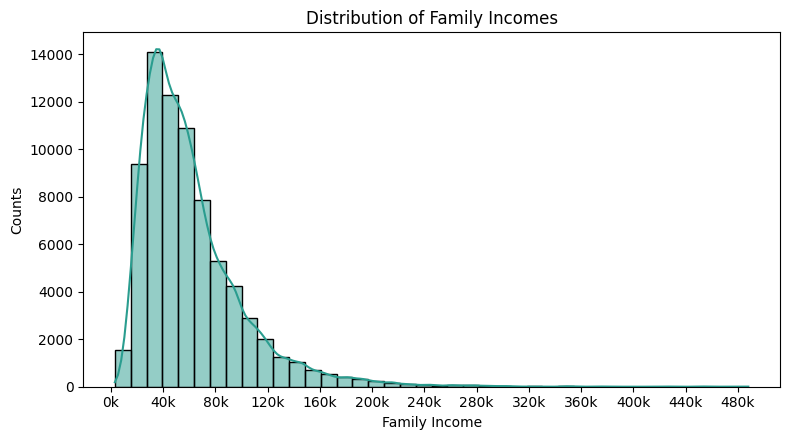

In [98]:
print("Family_Income mean: ", df_raw["Family_Income"].mean())
print("Family_Income median: ", df_raw["Family_Income"].median())
family_income_q1 = df_raw["Family_Income"].quantile(0.25)
family_income_q3 = df_raw["Family_Income"].quantile(0.75)
print("Family_Income IQ1: ", family_income_q1)
print("Family_Income IQ3: ", family_income_q3)
family_income_iqr = family_income_q3 - family_income_q1
print("Family_Income IQR: ", family_income_iqr)

# Check for outliers for family income
family_income_lower_bound = family_income_q1 - 1.5 * family_income_iqr
family_income_upper_bound = family_income_q3 + 1.5 * family_income_iqr

mask = (df_raw["Family_Income"] > family_income_upper_bound) | (df_raw["Family_Income"] < family_income_lower_bound)
n_outliers = mask.sum()
print("Family Income outliers: ", n_outliers)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(data=df_raw, x='Family_Income', bins=40, kde=True, color='#2A9D8F', ax=ax)
ax.set(title='Distribution of Family Incomes', xlabel='Family Income', ylabel='Counts')
ax.xaxis.set_major_locator(MultipleLocator(40000))
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1000:.0f}k'))
plt.tight_layout()
plt.show()

For family income there are about 3600 missing value out of the 79,000. Based on the distribution of the values, as seen above, we will use the median value in order to fill the missing data. The median is the perfect choice here because the distribution is right-skewed, because it is robust to the tail and represents a typical family better. The mean would shift a chunk of data upward, as the mean was pulled up due to the long right tail.

In [101]:
# Clean Family_Income missing values
df = df_raw.copy()
# Add column to flag missing family income
df["Family_Income_Missing"] = df_raw["Family_Income"].isna().astype(int)

display(df[df["Family_Income_Missing"] > 0])
median_family_income = df["Family_Income"].median()
df["Family_Income"] = df["Family_Income"].fillna(median_family_income)
display(df[df["Family_Income_Missing"] > 0])

,Student_ID,Age,Gender,First_Generation,Family_Income,Household_Size,Housing_Status,Scholarship,Tuition_Base,Semester,...,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,End_of_Semester_Status,Censored,Family_Income_Missing
8,STU_00003,24,Male,1,NaN,3,On-Campus,0,15000,2,...,2.97,87.6,80.0,1,0,1.2,0,Enrolled,0,1
31,STU_00010,20,Male,0,NaN,5,With Parents,0,25000,3,...,2.93,86.1,72.0,0,1,1.0,1,Dropped_Out,0,1
139,STU_00034,18,Male,1,NaN,6,Off-Campus,0,15000,4,...,2.94,88.4,64.0,0,0,2.9,0,Enrolled,0,1
176,STU_00043,24,Female,1,NaN,1,On-Campus,0,25000,4,...,2.09,78.6,57.0,0,4,1.0,1,Dropped_Out,0,1
177,STU_00044,17,Male,0,NaN,5,On-Campus,1,15000,1,...,3.24,91.1,74.0,0,1,1.5,0,Enrolled,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79185,STU_19987,22,Female,0,NaN,3,On-Campus,1,15000,3,...,3.13,84.3,77.0,0,0,1.0,0,Enrolled,1,1
79192,STU_19989,19,Female,1,NaN,4,Off-Campus,0,25000,2,...,2.86,89.8,36.0,0,1,1.0,0,Enrolled,0,1
79204,STU_19991,18,Male,1,NaN,3,Off-Campus,0,15000,4,...,2.49,89.3,53.0,1,0,1.0,0,Enrolled,0,1
79209,STU_19992,24,Male,0,NaN,3,On-Campus,0,25000,4,...,2.79,88.3,55.0,0,2,1.0,0,Enrolled,0,1


,Student_ID,Age,Gender,First_Generation,Family_Income,Household_Size,Housing_Status,Scholarship,Tuition_Base,Semester,...,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,End_of_Semester_Status,Censored,Family_Income_Missing
8,STU_00003,24,Male,1,52000.0,3,On-Campus,0,15000,2,...,2.97,87.6,80.0,1,0,1.2,0,Enrolled,0,1
31,STU_00010,20,Male,0,52000.0,5,With Parents,0,25000,3,...,2.93,86.1,72.0,0,1,1.0,1,Dropped_Out,0,1
139,STU_00034,18,Male,1,52000.0,6,Off-Campus,0,15000,4,...,2.94,88.4,64.0,0,0,2.9,0,Enrolled,0,1
176,STU_00043,24,Female,1,52000.0,1,On-Campus,0,25000,4,...,2.09,78.6,57.0,0,4,1.0,1,Dropped_Out,0,1
177,STU_00044,17,Male,0,52000.0,5,On-Campus,1,15000,1,...,3.24,91.1,74.0,0,1,1.5,0,Enrolled,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79185,STU_19987,22,Female,0,52000.0,3,On-Campus,1,15000,3,...,3.13,84.3,77.0,0,0,1.0,0,Enrolled,1,1
79192,STU_19989,19,Female,1,52000.0,4,Off-Campus,0,25000,2,...,2.86,89.8,36.0,0,1,1.0,0,Enrolled,0,1
79204,STU_19991,18,Male,1,52000.0,3,Off-Campus,0,15000,4,...,2.49,89.3,53.0,1,0,1.0,0,Enrolled,0,1
79209,STU_19992,24,Male,0,52000.0,3,On-Campus,0,25000,4,...,2.79,88.3,55.0,0,2,1.0,0,Enrolled,0,1
